# Model Predictive Control of an Inverted Double Pendulum

*Author: Hans Olischläger and Jerry M. Huang*

In this notebook, we use BayesFlow to connect Bayesian parameter inference with model
predictive control (MPC). We train an amortized posterior estimator on simulated
double-pendulum trajectories, then use it to infer the two rod masses from observed
motion. The resulting approximate posterior represents uncertainty about the masses
and supplies plausible parameter values for the controller to consider.

A double pendulum consists of two rods joined end to end, with the first attached to a
pivot. Here, we first observe its free motion around a fixed pivot, then consider a
control task in which the pivot moves with a cart. The workflow has two stages:

1. **Identification.** A double pendulum swings freely from near-horizontal under gravity.
   We observe the two joint angles over time and infer the rod masses $m_1, m_2$ with a
   BayesFlow posterior estimator.
2. **Robust control.** The same pendulum is mounted on a cart, hanging down, and must be
   swung up and balanced. The controller does not know the true masses, so it optimizes
   over a *scenario tree* built from the posterior instead of a single point estimate.

The posterior does more than quantify uncertainty: it connects BayesFlow's
inference results to control decisions by supplying representative mass scenarios for
the controller's predictions.

The MPC machinery lives in `misc/mpc/dp_control_helper.py` and uses the optional
[do-mpc](https://www.do-mpc.com/) library, which is based on [CasADi](https://web.casadi.org/).

The control implementation is adapted from the do-mpc example gallery:
<https://www.do-mpc.com/en/latest/example_gallery/DIP.html>

The final posterior-informed controller swings the pendulum upright while replanning
over representative mass scenarios:

![Robust swing-up of the inverted double pendulum](misc/mpc/control.gif)

## Setup

The robust-control section uses `do-mpc` and `scikit-learn`, optional dependencies that
are not installed with BayesFlow. Install them into the active environment from the
repository root with
[uv](https://docs.astral.sh/uv/):

```bash
uv pip install do-mpc scikit-learn
```

Restart the notebook kernel after installation if the import below does not pick it up.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

import bayesflow as bf

from misc.mpc import dp_control_helper as ctrl

## Model specification

We model a double pendulum swinging freely around a fixed pivot. The simulator describes
two uniform rigid rods of lengths
$l_1$ and $l_2$, moving under gravity without friction or external forcing. Both angles
$\theta_1(t)$ and $\theta_2(t)$ are measured relative to the downward vertical, so
$\theta_1=\theta_2=0$ is the hanging configuration.

### Equations of motion

Let $\delta=\theta_1-\theta_2$. The coupled Euler–Lagrange equations can be written as

$$
\begin{pmatrix}
h_4 & h_5\cos\delta \\
h_5\cos\delta & h_6
\end{pmatrix}
\begin{pmatrix}
\ddot\theta_1 \\
\ddot\theta_2
\end{pmatrix}
=
\begin{pmatrix}
-h_7\sin\theta_1-h_5\dot\theta_2^{\,2}\sin\delta \\
-h_8\sin\theta_2+h_5\dot\theta_1^{\,2}\sin\delta
\end{pmatrix},
$$

where the coefficients are defined as:

$$
\begin{aligned}
h_4 &= l_1^2\left(\frac{m_1}{3}+m_2\right), &
h_5 &= \frac{m_2l_1l_2}{2}, &
h_6 &= \frac{m_2l_2^2}{3}, \\
h_7 &= gl_1\left(\frac{m_1}{2}+m_2\right), &
h_8 &= \frac{gm_2l_2}{2}.
\end{aligned}
$$

The matrix on the left describes the rods' inertia and their coupling; the right-hand
side contains the gravitational and velocity-dependent terms. Solving this $2\times2$
system gives the angular accelerations. Together with $\dot\theta_i=\omega_i$, these
form a first-order ODE for the state $(\theta_1,\omega_1,\theta_2,\omega_2)$, which we
integrate using fourth-order Runge–Kutta (RK4).

### Priors and initial conditions

For each simulation, we independently draw the masses, lengths, and gravitational acceleration from bounded normal priors. The initial angles are drawn from the von Mises distribution concentrated around $\pi/2$ (near-horizontal), and both initial angular velocities are zero.

In [2]:
def bounded_normal(mean, std, low=-np.inf, high=np.inf):
    """Normal(mean, std) truncated to [low, high], bounds in original units."""
    a = (low - mean) / std
    b = (high - mean) / std
    return scipy.stats.truncnorm(a=a, b=b, loc=mean, scale=std)


PRIOR = {
    "g": bounded_normal(mean=9.81, std=0.01, low=0),
    "l1": bounded_normal(mean=1.0, std=0.1, low=0),
    "l2": bounded_normal(mean=1.0, std=0.1, low=0),
    "m1": bounded_normal(mean=1.0, std=0.1, low=0),
    "m2": bounded_normal(mean=1.0, std=0.1, low=0),
    "theta1": scipy.stats.vonmises(kappa=100.0, loc=np.pi / 2),
    "theta2": scipy.stats.vonmises(kappa=100.0, loc=np.pi / 2),
}


def prior(batch_shape):
    n = batch_shape[0]
    return {k: rv.rvs(size=(n, 1)).astype("float32") for k, rv in PRIOR.items()}

### Observation model

The observed data are the two angle trajectories,

$$
x=\big\{\big(\theta_1(t_k),\theta_2(t_k)\big)\big\}_{k=0}^{N-1},
\qquad t_k=k\,\Delta t,
$$

with $\Delta t=0.05\,\mathrm{s}$ and $N=200$. No measurement noise is added in this example:
given the parameters and initial conditions, the simulator returns a deterministic
trajectory. The adapter later subsamples these trajectories before passing them to BayesFlow.

In [3]:
T = 10.0
DT = 0.05
NUM_STEPS = int(T / DT)


def observation_model(batch_shape, g, l1, l2, m1, m2, theta1, theta2):
    """Integrate the free double pendulum with RK4 and return both angle trajectories."""
    g, l1, l2, m1, m2 = (np.asarray(v, dtype=np.float64)[..., 0] for v in (g, l1, l2, m1, m2))

    # coefficients of the Euler-Lagrange equations
    h4 = l1**2 * (m1 / 3.0 + m2)
    h5 = m2 * l1 * l2 / 2.0
    h6 = m2 * l2**2 / 3.0
    h7 = l1 * g * (m1 / 2.0 + m2)
    h8 = m2 * g * l2 / 2.0

    def derivs(y):
        ph1, w1, ph2, w2 = y[:, 0], y[:, 1], y[:, 2], y[:, 3]
        delta = ph1 - ph2
        cos_d, sin_d = np.cos(delta), np.sin(delta)
        det = h4 * h6 - h5**2 * cos_d**2
        rhs1 = -h7 * np.sin(ph1) - h5 * w2**2 * sin_d
        rhs2 = h5 * w1**2 * sin_d - h8 * np.sin(ph2)
        dydt = np.empty_like(y)
        dydt[:, 0] = w1
        dydt[:, 1] = (h6 * rhs1 - h5 * cos_d * rhs2) / det
        dydt[:, 2] = w2
        dydt[:, 3] = (h4 * rhs2 - h5 * cos_d * rhs1) / det
        return dydt

    n = batch_shape[0]
    y = np.zeros((n, 4))
    y[:, 0] = np.asarray(theta1, dtype=np.float64)[..., 0]
    y[:, 2] = np.asarray(theta2, dtype=np.float64)[..., 0]

    theta1_traj = np.empty((n, NUM_STEPS))
    theta2_traj = np.empty((n, NUM_STEPS))
    theta1_traj[:, 0], theta2_traj[:, 0] = y[:, 0], y[:, 2]

    for i in range(1, NUM_STEPS):
        k1 = derivs(y)
        k2 = derivs(y + 0.5 * DT * k1)
        k3 = derivs(y + 0.5 * DT * k2)
        k4 = derivs(y + DT * k3)
        y = y + (DT / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
        theta1_traj[:, i], theta2_traj[:, i] = y[:, 0], y[:, 2]

    return {
        "theta1_traj": theta1_traj[..., None].astype("float32"),
        "theta2_traj": theta2_traj[..., None].astype("float32"),
    }

We use BayesFlow's `make_simulator()` to encapsulate the entire data-generating process:

In [ ]:
simulator = bf.make_simulator(
  [prior, observation_model],
  obj_kwargs={
      "prior": {"is_batched": True},
      "observation_model": {"is_batched": True}
  },
)

sims = simulator.sample(200)

### Prior predictive check

The trajectories below are draws from the **prior predictive distribution**, generated
by sampling parameters from the priors and running the simulator. Before training BayesFlow,
we check whether their angle ranges, oscillation timescales, and variability are plausible
for the intended experiment.
Thick lines show the ensemble mean; shaded regions indicate ± one standard deviation.

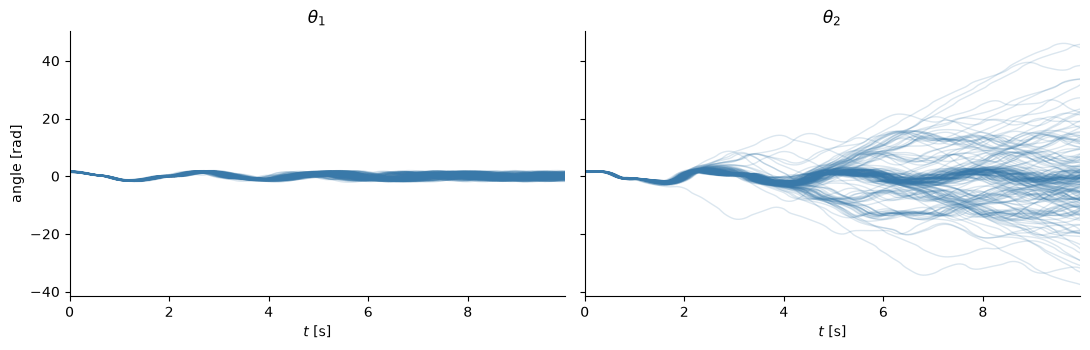

In [ ]:
t = np.arange(NUM_STEPS) * DT
color = "#3979A9"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

for ax, key, name in zip(axes, ["theta1_traj", "theta2_traj"], [r"$\theta_1$", r"$\theta_2$"]):
    trajectories = sims[key][..., 0]
    mean = trajectories.mean(axis=0)
    std = trajectories.std(axis=0)

    ax.plot(t, trajectories.T, color=color, alpha=0.18, lw=1, zorder=1)
    ax.set_xlabel("$t$ [s]")
    ax.set_title(name)
    ax.set_xlim(t[0], t[-1])
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("angle [rad]")
fig.tight_layout()

## The identification problem

Given the angle trajectories $x$, BayesFlow learns an approximate posterior over the rod masses:

$$
q_\phi(m_1,m_2\mid x)\approx p(m_1,m_2\mid x).
$$

Gravity, rod lengths, and initial angles vary across simulations and are marginalized as nuisance parameters. Scaling both masses by the same factor leaves the free motion unchanged. The trajectories can constrain the mass ratio $m_1/m_2$, but not the overall mass scale, so inference about the absolute masses remains dependent on the priors.

### Amortized posterior over the rod masses

The trajectories are subsampled to every fifth step before they reach the summary network,
and only $m_1, m_2$ are inferred. The remaining parameters are treated as known at control
time.

In [ ]:
adapter = (
    bf.Adapter()
    .to_array()
    .concatenate(["theta1_traj", "theta2_traj"], into="summary_variables")
    .take("summary_variables", indices=np.arange(0, NUM_STEPS, 5), axis=-2)
    .concatenate(["m1", "m2"], into="inference_variables")
)
adapter

Adapter([0: ToArray -> 1: Concatenate(['theta1_traj', 'theta2_traj'] -> 'summary_variables') -> 2: Take(include=['summary_variables']) -> 3: Concatenate(['m1', 'm2'] -> 'inference_variables') -> 4: Drop(['g', 'l1', 'l2', 'theta1', 'theta2'])])

We use BayesFlow's `BasicWorkflow` object to set up offline training and validation,
using a recurrent summary network and a spline-based coupling flow for inference.

In [10]:
NUM_TRAINING_SIMS = 10_000

training_data = simulator.sample(NUM_TRAINING_SIMS)
validation_data = simulator.sample(200)

In [ ]:
workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=bf.networks.CouplingFlow(
        transform="spline",
        depth=2
    ),
    summary_network=bf.networks.RecurrentNetwork(hidden_dim=64),
    initial_learning_rate=1e-3
)

history = workflow.fit_offline(
    training_data,
    epochs=100,
    batch_size=64,
    validation_data=validation_data
)

We can visualize the loss along with other diagnostics for estimating the rod masses.

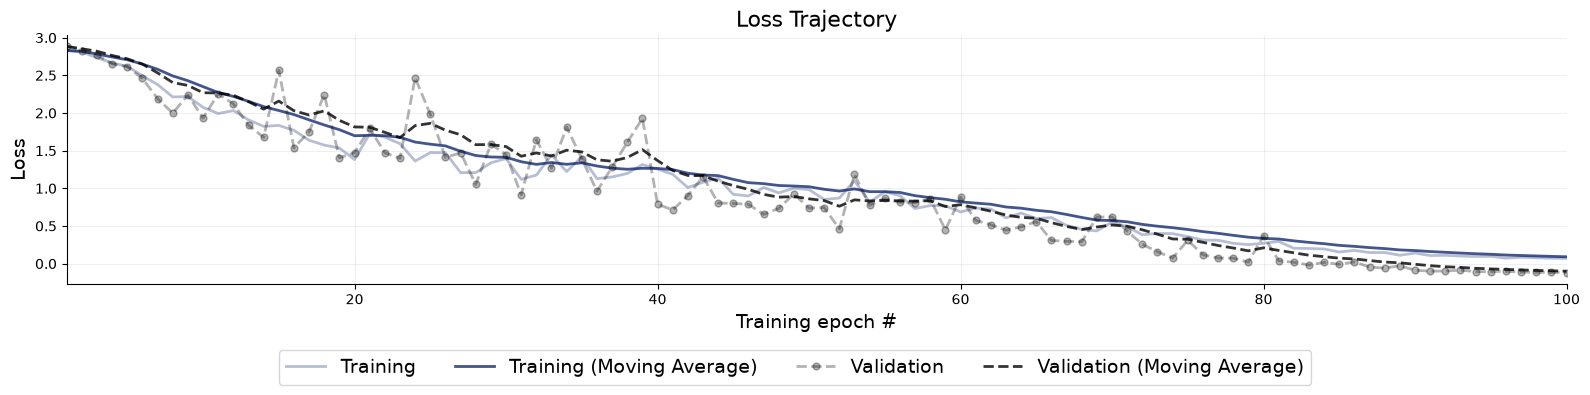

In [26]:
_ = bf.diagnostics.loss(history)

In [27]:
posterior_samples = workflow.sample(conditions=validation_data, num_samples=1000)

INFO:bayesflow:Sampling completed in 0.73 seconds.


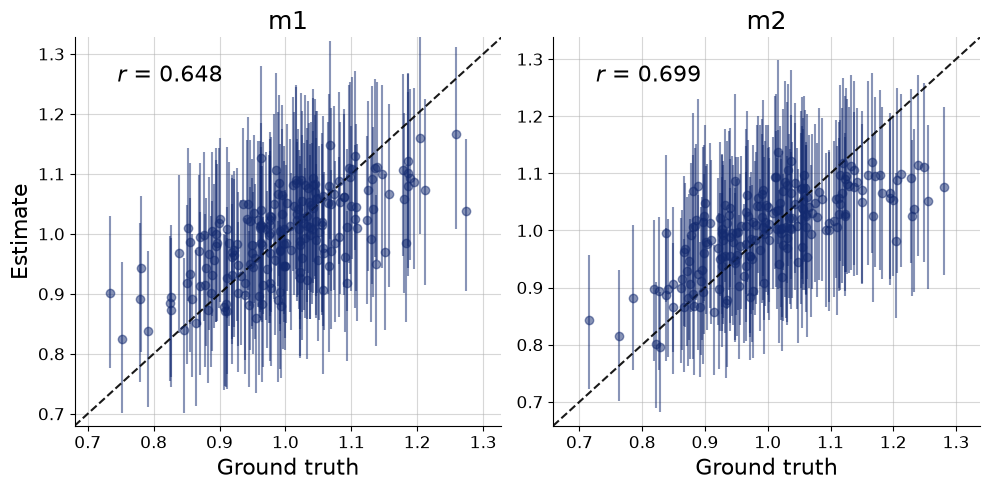

In [32]:
_ = bf.diagnostics.recovery(posterior_samples, validation_data, figsize=(10, 5))

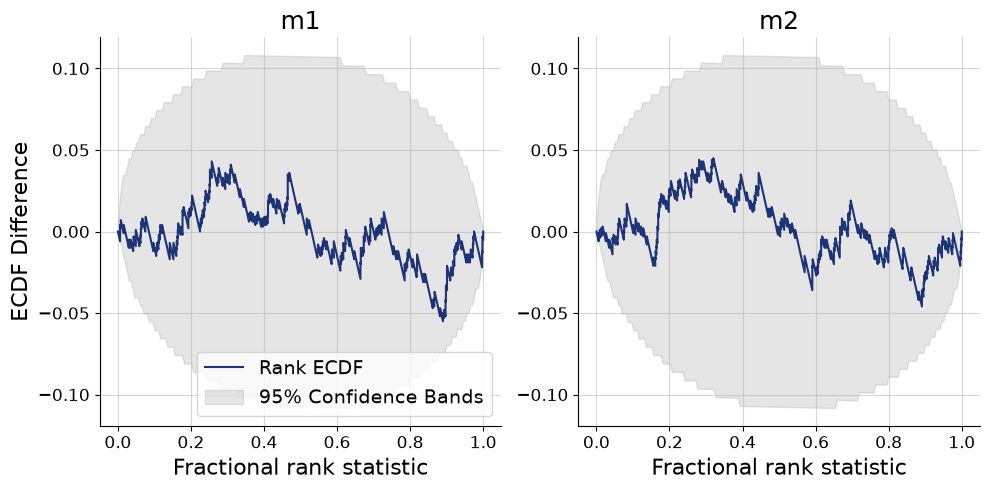

In [33]:
_ = bf.diagnostics.calibration_ecdf(posterior_samples, validation_data, figsize=(10, 5))

## Posterior for a single observation

For one new simulated trajectory, we visualize the inferred mass posterior together
with the true masses used to generate it.

INFO:bayesflow:Sampling completed in 0.16 seconds.


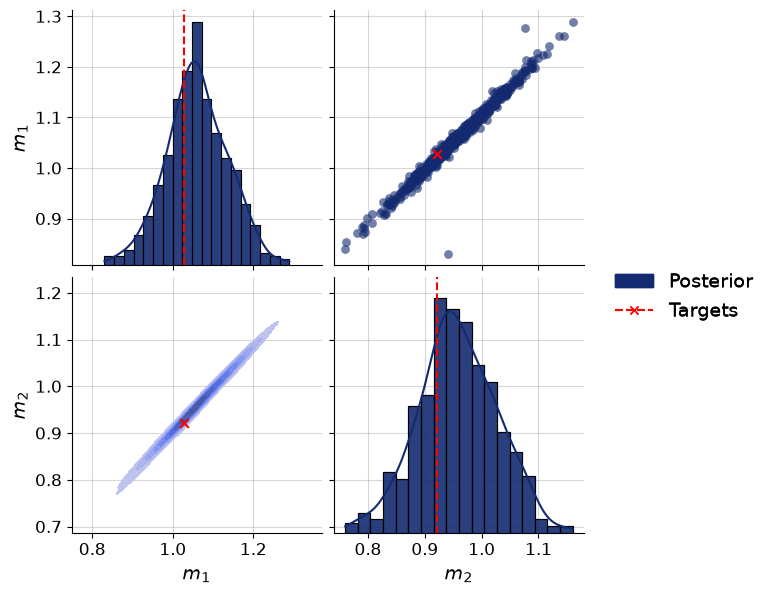

In [34]:
observation = workflow.simulate(1)

posterior_samples = workflow.sample(num_samples=500, conditions=observation)

f = bf.diagnostics.plots.pairs_posterior(
    posterior_samples,
    targets=observation,
    dataset_id=0,
    variable_keys=["m1", "m2"],
    variable_names=["$m_1$", "$m_2$"],
)

The near-perfect positive correlation in the posterior is a structural feature of the inverse problem. In the unforced, frictionless model, all inertial and gravitational terms are linear in the masses. Multiplying both $m_1$ and $m_2$ by the same constant therefore leaves the angle trajectories unchanged after the common factor cancels from the equations of motion. 

The observations identify the mass ratio $m_1/m_2$ much more strongly than the absolute mass scale, so posterior draws with nearly the same ratio form the diagonal ridge in the plot. The priors determine how far that ridge can extend. An input of known magnitude, a force or torque measurement, or fixing one mass would provide information about the missing absolute scale.

## Robust swing-up

We now pass BayesFlow's posterior for the observed free swing to the controller.
`pick_scenarios` clusters the joint posterior samples into three representative
$(m_1,m_2)$ pairs, which define the scenarios in do-mpc's prediction tree.

Rod lengths and gravity are assumed known at control time. The controller plans cart
forces across the mass scenarios, while the simulated pendulum evolves with the true
masses from the same observation. At each step, MPC applies the first planned force,
receives the updated state, and replans to swing up and balance the pendulum.

`n_robust=1` uses one branching level; additional levels enlarge the scenario tree and
increase computation. In the control model, angles are measured from the upward vertical,
so the upright target is zero.

In [20]:
M0 = 0.6  # cart mass [kg]
X0 = np.array([0.0, 0.99 * np.pi, 0.99 * np.pi, 0.0, 0.0, 0.0])  # hanging down, at rest

MPC_KWARGS = dict(
    n_horizon=100,
    n_robust=1,
    t_step=0.04,
    w_F=0.1,
    F_max=100,
    x_bound=1.3,
)

g_true = observation["g"][0, 0]
l1_true = observation["l1"][0, 0]
l2_true = observation["l2"][0, 0]
m1_true = observation["m1"][0, 0]
m2_true = observation["m2"][0, 0]

scenarios = ctrl.pick_scenarios({k: posterior_samples[k][0] for k in ("m1", "m2")}, 3)
print("scenario masses (m1, m2):\n", scenarios)
print(f"true masses: ({m1_true:.3f}, {m2_true:.3f})")

scenario masses (m1, m2):
 [[1.042599   0.9250405 ]
 [1.1464391  1.0146881 ]
 [0.936249   0.84211445]]
true masses: (1.095, 0.955)


In [ ]:
model = ctrl.build_model(M0, l1_true, l2_true, g_true)
mpc = ctrl.build_mpc(model, scenarios, **MPC_KWARGS)
sim = ctrl.build_simulator(model, m1_true, m2_true, t_step=MPC_KWARGS["t_step"])
est = ctrl.build_estimator(model)

result = ctrl.run_closed_loop(mpc, sim, est, X0, n_steps=100)

## Reproduce the animation

The animation at the top shows how the posterior-informed control actions move the
simulated pendulum (left). On the right, black curves trace the realized angles and
applied force, while blue curves show the controller's predictions for the three posterior
mass scenarios. These
predictions are updated at every control step, connecting BayesFlow's inferred mass
uncertainty to the evolving control plan.

After running the control cells above, here is how to generate the GIF. Rendering is
optional, so this cell is intentionally left unexecuted.

In [ ]:
ctrl.animate_with_predictions(
    result, l1_true, l2_true, skip=4, dpi=80, filename="control.gif"
)

That's it for this notebook! We learned how to use BayesFlow to infer a posterior over the
rod masses from observed motion and use that uncertainty to guide robust control. Now make
your own application that puts posterior uncertainty to work in predictions and decisions!